In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Relative path, so the notebook works on any machine where the CSV is in the same folder.
fitness_data = pd.read_csv("fitness_dataset.csv")

# Keep an untouched copy for the before/after comparison.
original_data = pd.read_csv("fitness_dataset.csv")

In [2]:
# First look at the raw rows to spot mixed formats and gaps before choosing cleaning rules.
fitness_data.head()

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,NaN,2.37,3.97,no,F,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,F,1
2,46,192,103,61.4,116.4,NaN,8.20,2.03,0,F,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,M,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,yes,F,1


In [3]:
# Data types and non-null counts, used for the types in the README data dictionary.
fitness_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                2000 non-null   int64  
 1   height_cm          2000 non-null   int64  
 2   weight_kg          2000 non-null   int64  
 3   heart_rate         2000 non-null   float64
 4   blood_pressure     2000 non-null   float64
 5   sleep_hours        1840 non-null   float64
 6   nutrition_quality  2000 non-null   float64
 7   activity_index     2000 non-null   float64
 8   smokes             2000 non-null   object 
 9   gender             2000 non-null   object 
 10  is_fit             2000 non-null   int64  
dtypes: float64(5), int64(4), object(2)
memory usage: 172.0+ KB


In [4]:
# Raw counts first: they show which spellings exist before the mapping hides them.
print("Raw value counts for 'smokes':")
print(fitness_data['smokes'].value_counts(dropna=False))

# Count the text-coded rows now: after the mapping the original labels are gone.
smokes_text_count = fitness_data['smokes'].astype(str).str.strip().str.lower().isin(['yes', 'no']).sum()

# Standardize 'smokes' to one numeric type; the raw column mixes numbers and text labels.
# Strip and lowercase first, so " Yes" and "yes" map to the same value.
fitness_data['smokes'] = (
    fitness_data['smokes']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'0': 0, '1': 1, 'no': 0, 'yes': 1})
)

print(f"\nTotal rows affected by 'smokes' standardization: {smokes_text_count}")

# Check: an unmapped label would silently become NaN, so the result must be only 0 and 1.
print("\nUnique values after standardization:")
fitness_data['smokes'].unique()

Raw value counts for 'smokes':
smokes
yes    711
0      581
no     518
1      190
Name: count, dtype: int64

Total rows affected by 'smokes' standardization: 1229

Unique values after standardization:


array([0, 1])

In [5]:
# Exact duplicates would double-count records in every later statistic.
print(f'Duplicate rows found: {fitness_data.duplicated().sum()}')

Duplicate rows found: 0


In [6]:
# Missing values per column, as counts and shares, to decide what needs imputation.

missing_count =  fitness_data.isnull().sum()
print("Count of missing values per column:")
print(missing_count)

percent_missing_column = (fitness_data.isnull().mean() * 100).round(2)
print("Percentage of missing values per column:")
print(percent_missing_column)

percent_missing = (fitness_data.isnull().sum().sum() / fitness_data.size * 100).round(2)
print(f"Percentage of total missing values on dataset: {percent_missing}%")

Count of missing values per column:
age                    0
height_cm              0
weight_kg              0
heart_rate             0
blood_pressure         0
sleep_hours          160
nutrition_quality      0
activity_index         0
smokes                 0
gender                 0
is_fit                 0
dtype: int64
Percentage of missing values per column:
age                  0.0
height_cm            0.0
weight_kg            0.0
heart_rate           0.0
blood_pressure       0.0
sleep_hours          8.0
nutrition_quality    0.0
activity_index       0.0
smokes               0.0
gender               0.0
is_fit               0.0
dtype: float64
Percentage of total missing values on dataset: 0.73%


In [7]:
# Range checks: values outside the accepted limits are treated as data entry errors.
# Age limits come from domain judgment.
min_limit = 10
max_limit = 100
impossible = fitness_data[(fitness_data["age"] < min_limit) | (fitness_data["age"] > max_limit)]
print(f'{len(impossible)} rows outside the valid range ({min_limit}-{max_limit}) for age')

print(fitness_data['age'].describe().round(2))

# Height limits come from domain judgment.
min_limit = 130
max_limit = 230
impossible = fitness_data[(fitness_data["height_cm"] < min_limit) | (fitness_data["height_cm"] > max_limit)]
print(f'{len(impossible)} rows outside the valid range ({min_limit}-{max_limit}) for height_cm')

print(fitness_data['height_cm'].describe().round(2))


0 rows outside the valid range (10-100) for age
count    2000.00
mean       49.11
std        17.93
min        18.00
25%        34.00
50%        49.00
75%        65.00
max        79.00
Name: age, dtype: float64
0 rows outside the valid range (130-230) for height_cm
count    2000.00
mean      174.53
std        14.37
min       150.00
25%       162.00
50%       174.00
75%       187.00
max       199.00
Name: height_cm, dtype: float64


In [8]:
# Heart rate limits come from domain judgment.
min_limit = 40
max_limit = 200
impossible = fitness_data[(fitness_data["heart_rate"] < min_limit) | (fitness_data["heart_rate"] > max_limit)]
print(f'{len(impossible)} rows outside the valid range ({min_limit}-{max_limit}) for heart_rate')

print(fitness_data['heart_rate'].describe().round(2))

# Blood pressure values represent systolic readings per the dataset documentation.
min_limit = 70
max_limit = 250
impossible = fitness_data[(fitness_data["blood_pressure"] < min_limit) | (fitness_data["blood_pressure"] > max_limit)]
print(f'{len(impossible)} rows outside the valid range ({min_limit}-{max_limit}) for blood_pressure')

print(fitness_data['blood_pressure'].describe().round(2))

0 rows outside the valid range (40-200) for heart_rate
count    2000.00
mean       70.29
std        11.85
min        45.00
25%        62.10
50%        70.25
75%        78.43
max       118.60
Name: heart_rate, dtype: float64
0 rows outside the valid range (70-250) for blood_pressure
count    2000.00
mean      119.91
std        14.58
min        90.00
25%       109.70
50%       120.00
75%       129.80
max       171.20
Name: blood_pressure, dtype: float64


In [9]:
# Valid nutrition_quality values come from the dataset documentation.
min_limit = 0
max_limit = 10
impossible = fitness_data[(fitness_data["nutrition_quality"] < min_limit) | (fitness_data["nutrition_quality"] > max_limit)]
print(f'{len(impossible)} rows outside the {min_limit}-{max_limit} range for nutrition_quality')

print(fitness_data['nutrition_quality'].describe().round(2))

# Valid activity_index values come from the dataset documentation.
min_limit = 1
max_limit = 5
impossible = fitness_data[(fitness_data["activity_index"] < min_limit) | (fitness_data["activity_index"] > max_limit)]
print(f'{len(impossible)} rows outside the {min_limit}-{max_limit} range for activity_index')

print(fitness_data['activity_index'].describe().round(2))

# 'smokes' was standardized earlier, so it is not checked again here.

# Allowed gender values come from the dataset documentation.
print(fitness_data['gender'].value_counts(dropna=False))

# Allowed is_fit values come from the dataset documentation.
print(fitness_data['is_fit'].value_counts(dropna=False))

0 rows outside the 0-10 range for nutrition_quality
count    2000.00
mean        5.04
std         2.86
min         0.00
25%         2.55
50%         5.06
75%         7.47
max        10.00
Name: nutrition_quality, dtype: float64
0 rows outside the 1-5 range for activity_index
count    2000.00
mean        3.00
std         1.14
min         1.00
25%         2.04
50%         2.98
75%         3.95
max         4.99
Name: activity_index, dtype: float64
gender
F    1030
M     970
Name: count, dtype: int64
is_fit
0    1201
1     799
Name: count, dtype: int64


In [10]:
# Exploratory check only: weight alone cannot show an error without height.
# The removal rule uses BMI, which accounts for height (see below).
min_limit = 40
max_limit = 230
impossible_weight = fitness_data[(fitness_data["weight_kg"] < min_limit) | (fitness_data["weight_kg"] > max_limit)]
print(f"{len(impossible_weight)} rows flagged by initial weight bounds")

print(fitness_data['weight_kg'].describe().round(2))

23 rows flagged by initial weight bounds
count    2000.00
mean       83.54
std        25.85
min        30.00
25%        64.00
50%        83.00
75%       102.00
max       250.00
Name: weight_kg, dtype: float64


In [11]:
count = 10
print(f'the {count} smallest:')
print(fitness_data['weight_kg'].nsmallest(count))
print(f'the {count} largest:')
print(fitness_data['weight_kg'].nlargest(count))

the 10 smallest:
30      30
1320    30
1487    30
1692    30
1765    30
37      35
52      35
159     35
201     35
348     35
Name: weight_kg, dtype: int64
the 10 largest:
268     250
670     250
933     250
1960    250
400     220
487     220
968     220
1086    220
1257    220
1361    220
Name: weight_kg, dtype: int64


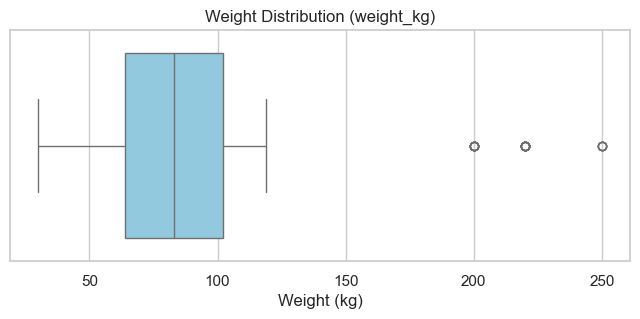

In [12]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=fitness_data['weight_kg'], color='skyblue')

plt.title('Weight Distribution (weight_kg)', fontsize=12)
plt.xlabel('Weight (kg)')

# Visual check only; the exact IQR fence is computed below.
plt.show()

In [13]:
# BMI = weight (kg) / height (m)^2; height is stored in cm, hence the division by 100.
fitness_data['bmi'] = (fitness_data['weight_kg'] / (fitness_data['height_cm']/100) ** 2).round(2)

print(fitness_data['bmi'].describe())

# Inspect both tails before choosing thresholds.
print("\nLowest BMIs:")
print(fitness_data[['height_cm', 'weight_kg', 'bmi']].nsmallest(5, 'bmi'))

print("\nHighest BMIs:")
print(fitness_data[['height_cm', 'weight_kg', 'bmi']].nlargest(5, 'bmi'))

count    2000.000000
mean       27.983690
std        10.027215
min         8.840000
25%        20.690000
50%        26.920000
75%        33.337500
max       109.640000
Name: bmi, dtype: float64

Lowest BMIs:
      height_cm  weight_kg   bmi
431         199         35  8.84
30          181         30  9.16
37          193         35  9.40
569         192         35  9.49
1765        177         30  9.58

Highest BMIs:
      height_cm  weight_kg     bmi
933         151        250  109.64
1960        155        250  104.06
1361        150        220   97.78
268         160        250   97.66
487         153        220   93.98


In [14]:
# The IQR fence is computed only for comparison; the removal decision uses the BMI rule.
q1 = fitness_data['weight_kg'].quantile(0.25)
q3 = fitness_data['weight_kg'].quantile(0.75)
iqr = q3 - q1
upper_iqr_fence = q3 + (1.5 * iqr)

# BMI boundaries are a judgment call based on physiological limits.
BMI_MIN = 12.0
BMI_MAX = 60.0

# Flag first and count, so the impact is visible before any row is removed.
fitness_data['weight_outlier'] = (fitness_data['bmi'] < BMI_MIN) | (fitness_data['bmi'] > BMI_MAX)

outlier_count = fitness_data['weight_outlier'].sum()
total_rows = len(fitness_data)
outlier_pct = (outlier_count / total_rows) * 100

iqr_exceeded_count = (fitness_data['weight_kg'] > upper_iqr_fence).sum()

print(f"Total initial rows: {total_rows}")
print(f"Weight 1.5x IQR Upper Fence: {upper_iqr_fence:.2f} kg")
print(f"Rows exceeding IQR upper fence (> {upper_iqr_fence:.2f} kg): {iqr_exceeded_count}")
print(f"Rows marked as weight_outlier (BMI < {BMI_MIN} or > {BMI_MAX}): {outlier_count} ({outlier_pct:.2f}% of total data)")

Total initial rows: 2000
Weight 1.5x IQR Upper Fence: 159.00 kg
Rows exceeding IQR upper fence (> 159.00 kg): 21
Rows marked as weight_outlier (BMI < 12.0 or > 60.0): 35 (1.75% of total data)


### Why BMI instead of fixed weight limits

Weight alone cannot separate a data error from a tall or heavy person. BMI also uses height, so it flags height–weight combinations that are physically implausible. The 1.5×IQR rule is shown only for comparison. Decision: remove the flagged rows; the counts are printed above.

In [15]:
# Save the removed rows so every removal can be reviewed or reversed.
removed_outliers = fitness_data[fitness_data['weight_outlier']].copy()

# The flag is always True in this file, so it adds no information.
removed_outliers = removed_outliers.drop(columns=['weight_outlier'])

removed_outliers.to_csv('fitness_outliers_removed.csv', index=False)
print(f"Exported {len(removed_outliers)} outlier rows to 'fitness_outliers_removed.csv'")

Exported 35 outlier rows to 'fitness_outliers_removed.csv'


In [16]:
# These rows are physically implausible and a small share of the data, so removing them costs little.

fitness_data = fitness_data[~fitness_data['weight_outlier']].copy()

print(f"Rows before removal: {total_rows}")
print(f"Rows after removal: {len(fitness_data)}")
print(f"Total rows removed: {outlier_count} ({outlier_pct:.2f}%)")

# The flag was only needed to count and filter, so it is not kept (unlike sleep_hours_was_missing).
fitness_data = fitness_data.drop(columns=['weight_outlier'])

# Weight after cleaning, for the before/after comparison in the README.
print("\nWeight statistics after cleaning:")
print(fitness_data['weight_kg'].describe().round(2))

Rows before removal: 2000
Rows after removal: 1965
Total rows removed: 35 (1.75%)

Weight statistics after cleaning:
count    1965.00
mean       82.51
std        21.75
min        30.00
25%        64.00
50%        83.00
75%       101.00
max       220.00
Name: weight_kg, dtype: float64


In [17]:
# Confirm the filter worked: the BMI extremes must now be inside the accepted limits.
print(fitness_data['bmi'].describe().round(2))

print("\nLowest BMIs:")
print(fitness_data[['height_cm', 'weight_kg', 'bmi']].nsmallest(5, 'bmi'))

print("\nHighest BMIs:")
print(fitness_data[['height_cm', 'weight_kg', 'bmi']].nlargest(5, 'bmi'))

count    1965.00
mean       27.62
std         8.56
min        12.08
25%        20.72
50%        26.89
75%        33.18
max        55.55
Name: bmi, dtype: float64

Lowest BMIs:
      height_cm  weight_kg    bmi
932         193         45  12.08
631         170         35  12.11
1305        170         35  12.11
1674        170         35  12.11
1022        191         45  12.34

Highest BMIs:
      height_cm  weight_kg    bmi
1585        199        220  55.55
1357        150        119  52.89
1610        151        119  52.19
1205        150        117  52.00
994         151        117  51.31


In [18]:
# Only sleep_hours has gaps, so it is the only column that needs imputation.

# "Impossible" values are errors; "extreme" values are rare but possible, so they are only reviewed.
impossible = fitness_data[(fitness_data["sleep_hours"] < 0) | (fitness_data["sleep_hours"] > 24)]
print(f'{len(impossible)} rows with impossible sleep_hours values')
extreme = fitness_data[(fitness_data["sleep_hours"] < 3) | (fitness_data["sleep_hours"] > 14)]
print(f'{len(extreme)} rows with extreme sleep_hours values')


0 rows with impossible sleep_hours values
0 rows with extreme sleep_hours values


In [19]:
# Hypothesis: sleep depends on age group, gender and activity level; if so, group medians would
# impute better than the global median.

# Helper groups, created only for this test and removed before export.

# Age bands: the lower edge sits just below the minimum age because intervals exclude their left edge,
# so the youngest person falls in the first band.
fitness_data['age_group'] = pd.cut(fitness_data['age'], bins=[17, 25, 50, 100], labels=['young', 'adult', 'senior'])

# Group size matters: tiny groups give unstable medians.
count_groups = fitness_data.groupby('age_group', observed=True).size()
print(f'Rows per {count_groups}')

# Bins are right-inclusive: a score of exactly 2 is "low" and exactly 4 is "medium".
# The lower edge sits just below the minimum score so the minimum falls in the first bin.
fitness_data['activity_index_group'] = pd.cut(fitness_data['activity_index'], bins=[0.9, 2, 4, 5], labels=['low', 'medium', 'high'])
count_groups = fitness_data.groupby('activity_index_group', observed=True).size()
print(f'\nRows per {count_groups}')

Rows per age_group
young     250
adult     778
senior    937
dtype: int64

Rows per activity_index_group
low        479
medium    1028
high       458
dtype: int64


In [20]:
# If the medians barely differ across groups, grouping is unlikely to help.
print('\nanalyzing the medians of each group\n')

median_for_group = fitness_data.groupby('age_group', observed=True)['sleep_hours'].median()
print(f'median for age_group: {median_for_group}')

median_for_group = fitness_data.groupby('activity_index_group', observed=True)['sleep_hours'].median()
print(f'\nmedian for activity_index_group: {median_for_group}')

median_for_group = fitness_data.groupby('gender', observed=True)['sleep_hours'].median()
print(f'\nmedian for gender: {median_for_group}')

# Conclusion: medians barely differ by gender, age group or activity group, so grouping may not help.


analyzing the medians of each group

median for age_group: age_group
young     7.7
adult     7.6
senior    7.5
Name: sleep_hours, dtype: float64

median for activity_index_group: activity_index_group
low       7.5
medium    7.6
high      7.5
Name: sleep_hours, dtype: float64

median for gender: gender
F    7.5
M    7.6
Name: sleep_hours, dtype: float64


In [21]:
# Masking test: hide a random share of the known values, impute them with each method, and compare with the true values.

maes_global = []
maes_grouped = []
nan_count = 0

# Use only rows with a known sleep value, so the true value exists for every hidden row.
test_df = fitness_data[fitness_data['sleep_hours'].notna()].copy()

for seed in range(50):
    # Pick rows to hide at random; the seed makes each repeat reproducible.
    sample_idx = test_df.sample(frac=0.10, random_state=seed).index
    # Read the true values before they are overwritten with NaN.
    y_true = test_df.loc[sample_idx, 'sleep_hours']

    # Work on a copy so each repeat starts from the full set of known values.
    train_df = test_df.copy()
    train_df.loc[sample_idx, 'sleep_hours'] = np.nan

    # Method A: global median.
    global_median = train_df['sleep_hours'].median()
    y_pred_global = [global_median] * len(sample_idx)

    # Method B: median within each helper group.
    group_median = train_df.groupby(['age_group','gender', 'activity_index_group'], observed=True)['sleep_hours'].transform('median')
    y_pred_group = group_median.loc[sample_idx]

    # Count predictions that came back NaN: a group with no observed values left gets no prediction.
    nan_count += y_pred_group.isna().sum()

    # MAE is in hours, the same unit as sleep_hours, so it is easy to interpret.
    maes_global.append(np.mean(np.abs(y_true - y_pred_global)))
    maes_grouped.append(np.mean(np.abs(y_true - y_pred_group)))

# Average across all seeds, so the result does not depend on a single random split.
print(f"Total NaN predictions across all seeds: {nan_count}")
print(f"Average Global Median Error (MAE): {np.mean(maes_global):.4f} hours")
print(f"Average Grouped Median Error (MAE): {np.mean(maes_grouped):.4f} hours")

# Decision: grouped medians did not reduce the error, so the simpler global median is used.

Total NaN predictions across all seeds: 0
Average Global Median Error (MAE): 1.2010 hours
Average Grouped Median Error (MAE): 1.2105 hours


In [22]:
# Flag before filling, so users of the data can exclude or weight imputed values.
fitness_data['sleep_hours_was_missing'] = fitness_data['sleep_hours'].isna()

# Count after the outlier removal, so this can be lower than the raw count of missing values.
imputed_count = fitness_data['sleep_hours_was_missing'].sum()
print(f"Total rows imputed for sleep_hours: {imputed_count}")

# Fill with the global median (chosen in the comparison above).
global_median = fitness_data['sleep_hours'].median()
fitness_data['sleep_hours'] = fitness_data['sleep_hours'].fillna(global_median)

print(f"Global median sleep hours used for imputation: {global_median}")

print(f"Missing values remaining in sleep_hours: {fitness_data['sleep_hours'].isnull().sum()}")

fitness_data['sleep_hours'].describe().round(2)

Total rows imputed for sleep_hours: 156
Global median sleep hours used for imputation: 7.5
Missing values remaining in sleep_hours: 0


count    1965.00
mean        7.51
std         1.45
min         4.00
25%         6.60
50%         7.50
75%         8.40
max        12.00
Name: sleep_hours, dtype: float64

In [23]:
# Drop temporary helper columns used only for imputation testing.
fitness_data = fitness_data.drop(columns=['age_group', 'activity_index_group'])

In [24]:
# Summary used for the before/after table in the README.
summary_df = pd.DataFrame({
    'Metric': ['Total Rows', 'Missing sleep_hours', 'Weight/BMI Outliers Removed', 'Total Columns'],
    'Original Data': [len(original_data), original_data['sleep_hours'].isnull().sum(), 0, len(original_data.columns)],
    'Cleaned Data': [len(fitness_data), fitness_data['sleep_hours'].isnull().sum(), outlier_count, len(fitness_data.columns)]
})

print("--- Data Cleaning Summary ---")
print(summary_df)

--- Data Cleaning Summary ---
                        Metric  Original Data  Cleaned Data
0                   Total Rows           2000          1965
1          Missing sleep_hours            160             0
2  Weight/BMI Outliers Removed              0            35
3                Total Columns             11            13


In [25]:
# Export both delivered formats; index=False because row positions have gaps after the removal.
fitness_data.to_csv("fitness_clean.csv", index=False)
fitness_data.to_excel("fitness_clean.xlsx", index=False)

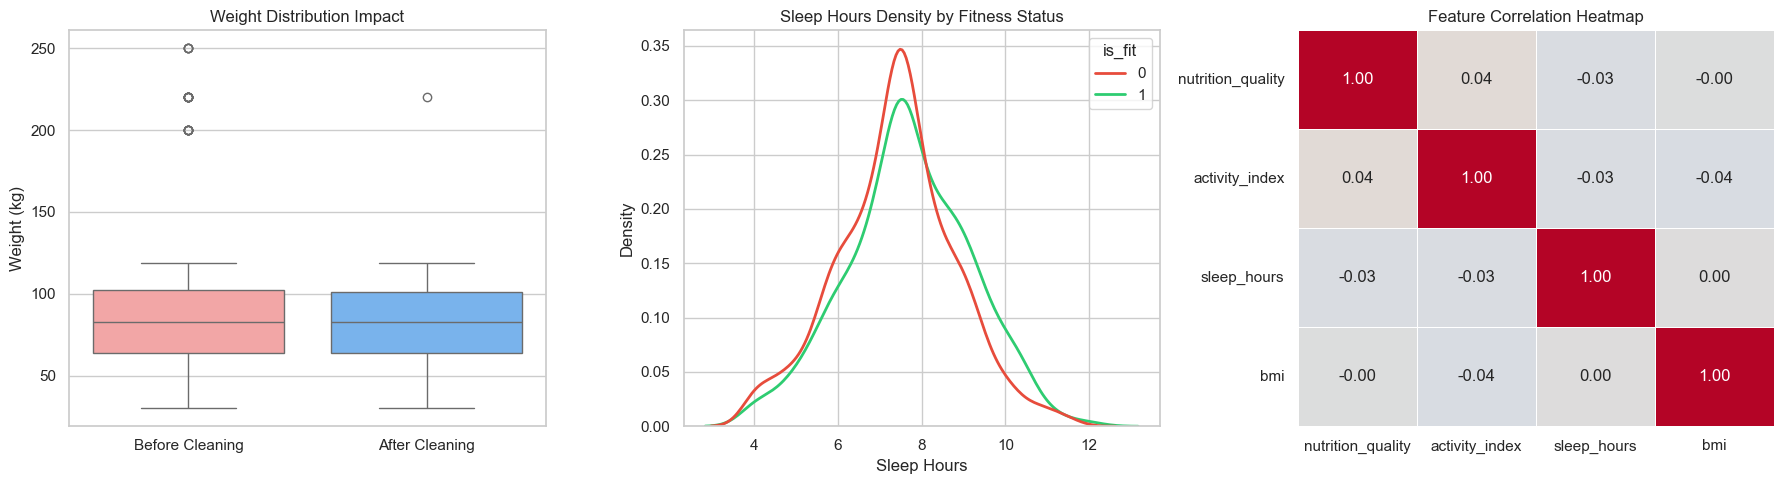

In [26]:
plt.figure(figsize=(18, 5))

# Plot 1: weight before vs. after cleaning.
# Aligned by index, so removed rows appear as NaN and the boxplot ignores them.
plt.subplot(1, 3, 1)

weight_comparison = pd.DataFrame({
    'Before Cleaning': original_data['weight_kg'],
    'After Cleaning': fitness_data['weight_kg']
})

sns.boxplot(data=weight_comparison, palette=['#ff9999', '#66b3ff'])
plt.title('Weight Distribution Impact', fontsize=12)
plt.ylabel('Weight (kg)')

# Plot 2: sleep density by fitness status.
# Each group is normalized separately, so shapes compare despite different group sizes.
plt.subplot(1, 3, 2)

sns.kdeplot(
    data=fitness_data, 
    x='sleep_hours', 
    hue='is_fit', 
    fill=False, 
    common_norm=False, 
    palette={0: '#e74c3c', 1: '#2ecc71'},
    linewidth=2
)

plt.title('Sleep Hours Density by Fitness Status', fontsize=12)
plt.xlabel('Sleep Hours')
plt.ylabel('Density')

# Plot 3: correlation heatmap.
plt.subplot(1, 3, 3)

# Continuous measures only; the binary columns would need a different statistic.
corr_matrix = fitness_data[['nutrition_quality', 'activity_index', 'sleep_hours', 'bmi']].corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    cbar=False,
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap', fontsize=12)

# Save before show(): some backends clear the figure after it is displayed.
plt.tight_layout()
plt.savefig('quick_insights.png', dpi=300)
plt.show()

Sleep hours correlation (Full Cleaned Dataset):
nutrition_quality   -0.031
activity_index      -0.030
sleep_hours          1.000
bmi                  0.004
Name: sleep_hours, dtype: float64

Sleep hours correlation (Observed Data Only - No Imputation):
nutrition_quality   -0.032
activity_index      -0.032
sleep_hours          1.000
bmi                  0.004
Name: sleep_hours, dtype: float64


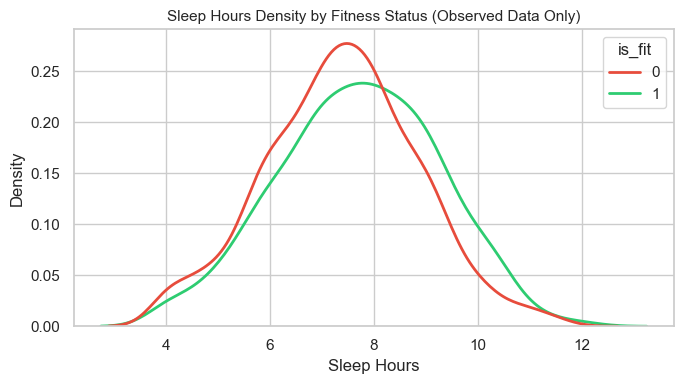

In [27]:
# Imputed rows all share one value, which can add a peak and flatten correlations; this checks whether the results depend on them.
observed_data = fitness_data[~fitness_data['sleep_hours_was_missing']].copy()

corr_all = fitness_data[['nutrition_quality', 'activity_index', 'sleep_hours', 'bmi']].corr()
corr_observed = observed_data[['nutrition_quality', 'activity_index', 'sleep_hours', 'bmi']].corr()

print("Sleep hours correlation (Full Cleaned Dataset):")
print(corr_all['sleep_hours'].round(3))

print("\nSleep hours correlation (Observed Data Only - No Imputation):")
print(corr_observed['sleep_hours'].round(3))

# Same density plot without imputed rows, to see whether the median peak drives the overlap.
plt.figure(figsize=(7, 4))
sns.kdeplot(
    data=observed_data, 
    x='sleep_hours', 
    hue='is_fit', 
    fill=False, 
    common_norm=False, 
    palette={0: '#e74c3c', 1: '#2ecc71'},
    linewidth=2
)
plt.title('Sleep Hours Density by Fitness Status (Observed Data Only)', fontsize=11)
plt.xlabel('Sleep Hours')
plt.ylabel('Density')
plt.tight_layout()
plt.show()